In [33]:
# Importar librerías necesarias para el modelado predictivo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Definir una semilla para garantizar la reproducibilidad del modelo
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("¡Librerías importadas y semilla configurada correctamente!")

¡Librerías importadas y semilla configurada correctamente!


In [34]:
# # Cargar el archivo de demanda diaria
df = pd.read_csv('demanda_diaria.csv')

# Convertir fecha a tipo fecha y ordenar cronológicamente
df['fecha'] = pd.to_datetime(df['fecha'])
df = df.sort_values('fecha').reset_index(drop=True)

# Revisar valores nulos por columna
print(df.isna().sum())

# Variable objetivo demanda del día
y = df['demanda_kwh']

fecha                0
demanda_kwh          0
evento_programado    0
dtype: int64


In [35]:
# Crear variables temporales
df['dia_semana'] = df['fecha'].dt.dayofweek
df['mes'] = df['fecha'].dt.month

In [22]:
# Creación de variables de rezago y media móvil sobre la variable real de demanda
df['lag_1'] = df['demanda_kwh'].shift(1)
df['lag_7'] = df['demanda_kwh'].shift(7)
df['media_movil_7'] = df['demanda_kwh'].shift(1).rolling(window=7).mean()

# Limpiar los valores nulos iniciales generados por los rezagos
df = df.dropna().reset_index(drop=True)

print("¡Dataset real cargado y preparado exitosamente!")
display(df.head())

¡Dataset real cargado y preparado exitosamente!


,fecha,demanda_kwh,evento_programado,dia_semana,mes,lag_1,lag_7,media_movil_7
0,2026-01-08,16568.10,0,3,1,17456.69,17856.31,16792.854286
1,2026-01-09,15495.83,0,4,1,16568.10,17379.10,16608.824286
2,2026-01-10,15370.24,0,5,1,15495.83,15720.70,16339.785714
3,2026-01-11,15652.73,0,6,1,15370.24,15694.05,16289.720000
4,2026-01-12,16919.53,1,0,1,15652.73,16505.77,16283.817143


In [23]:
#Definir las 6 características exactas exigidas por el enunciado
features = ["lag_1", "lag_7", "media_movil_7", "dia_semana", "mes", "evento_programado"]
X = df[features]
y = df["demanda_kwh"]

In [24]:
# Calcular el punto de corte para la partición cronológica
train_size = int(len(df) * 0.8)

# Dividir los datos de entrenamiento y prueba y no lo mezclamos
X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]
y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

In [25]:
# Guardamos las fechas correspondientes al conjunto de prueba
fechas_test = df['fecha'].iloc[train_size:]

print(f"Total de registros procesados: {len(df)}")
print(f"Tamaño de X_train: {len(X_train)}")
print(f"Tamaño de X_test (y sus fechas): {len(X_test)}")

Total de registros procesados: 173
Tamaño de X_train: 138
Tamaño de X_test (y sus fechas): 35


In [26]:
# Entrenar el Baseline
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)
y_pred_dummy = dummy_model.predict(X_test)

# Entrenar el Modelo Base
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

In [27]:
# Calcular métricas del Baseline
mae_dummy = mean_absolute_error(y_test, y_pred_dummy)
rmse_dummy = np.sqrt(mean_squared_error(y_test, y_pred_dummy))
r2_dummy = r2_score(y_test, y_pred_dummy)

# Calcular métricas de la Regresión Lineal
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

# Porcentaje de mejora del MAE
mejora_mae = ((mae_dummy - mae_lr) / mae_dummy) * 100

print("=== MÉTRICAS BASELINE (Dummy) ===")
print(f"MAE: {mae_dummy:.4f} | RMSE: {rmse_dummy:.4f} | R2: {r2_dummy:.4f}\n")

print("=== MÉTRICAS MODELO BASE (Linear Regression) ===")
print(f"MAE: {mae_lr:.4f} | RMSE: {rmse_lr:.4f} | R2: {r2_lr:.4f}\n")

print(f"Porcentaje de mejora del MAE respecto al baseline: {mejora_mae:.2f}%")

=== MÉTRICAS BASELINE (Dummy) ===
MAE: 1194.5730 | RMSE: 1391.6764 | R2: -1.9384

=== MÉTRICAS MODELO BASE (Linear Regression) ===
MAE: 298.7650 | RMSE: 378.7246 | R2: 0.7824

Porcentaje de mejora del MAE respecto al baseline: 74.99%


In [36]:
import json

# Creamos el diccionario plano con los nombres de claves exactos del contrato
metricas_dict = {
    "mae_baseline": float(mae_dummy),
    "mae_modelo": float(mae_lr),
    "rmse_modelo": float(rmse_lr),
    "r2_modelo": float(r2_lr),
    "mejora_mae_pct": float(mejora_mae)
}

with open("metricas.json", "w") as f:
    json.dump(metricas_dict, f, indent=4)

In [37]:
# hay que generar el DataFrame con los nombres de columnas exactos y formato de fecha limpio
df_predicciones = pd.DataFrame({
    "fecha": pd.to_datetime(fechas_test).dt.strftime('%Y-%m-%d'),
    "real": y_test.values,
    "baseline": y_pred_dummy,
    "prediccion": y_pred_lr
})

df_predicciones.to_csv("predicciones.csv", index=False)

print("¡Archivos 'metricas.json' y 'predicciones.csv' actualizados con el contrato exacto del EP2!")
display(df_predicciones.head())

¡Archivos 'metricas.json' y 'predicciones.csv' actualizados con el contrato exacto del EP2!


,fecha,real,baseline,prediccion
138,2026-05-26,18800.00,17281.821304,18603.319450
139,2026-05-27,19294.76,17281.821304,18371.300370
140,2026-05-28,18761.74,17281.821304,18254.034120
141,2026-05-29,17890.43,17281.821304,17746.713486
142,2026-05-30,17112.40,17281.821304,17218.995397


In [30]:
# Imprimir la primera y la última fecha de prueba
print(f"Primera fecha de prueba: {fechas_test.iloc[0]}")
print(f"Última fecha de prueba: {fechas_test.iloc[-1]}")

# Ver tus métricas calculadas
print(f"MAE Baseline: {mae_dummy:.4f}")
print(f"MAE Modelo: {mae_lr:.4f}")
print(f"% de Mejora: {mejora_mae:.2f}%")

Primera fecha de prueba: 2026-05-26 00:00:00
Última fecha de prueba: 2026-06-29 00:00:00
MAE Baseline: 1194.5730
MAE Modelo: 298.7650
% de Mejora: 74.99%


In [ ]:
# DESCARGAR LOS ARCHIVOS
from google.colab import files
files.download('predicciones.csv')
files.download('metricas.json')



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

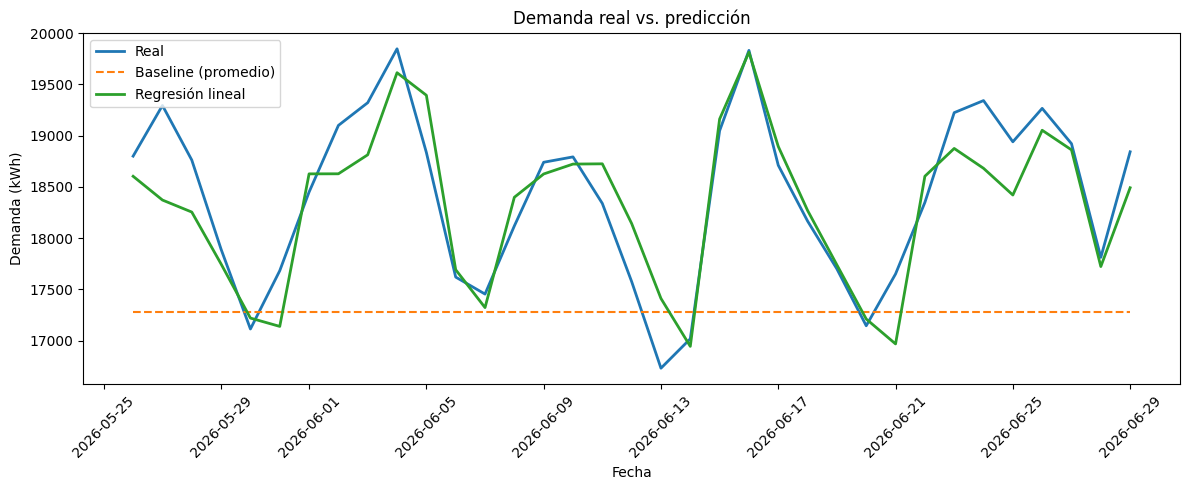

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
# Gráfico completo: Tamaño, líneas, títulos, leyenda y guardado
plt.figure(figsize=(12, 5))

plt.plot(fechas_test, y_test, label="Real", linewidth=2)
plt.plot(fechas_test, y_pred_dummy, label="Baseline (promedio)", linestyle="--")
plt.plot(fechas_test, y_pred_lr, label="Regresión lineal", linewidth=2)

plt.title("Demanda real vs. predicción")
plt.xlabel("Fecha")
plt.ylabel("Demanda (kWh)")
plt.legend(loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()

# Guardar la imagen antes de mostrarla
plt.savefig("grafico_prediccion.png", dpi=150)
plt.show()

# DESCARGAR LA GRÁFICA
from google.colab import files
files.download('grafico_prediccion.png')